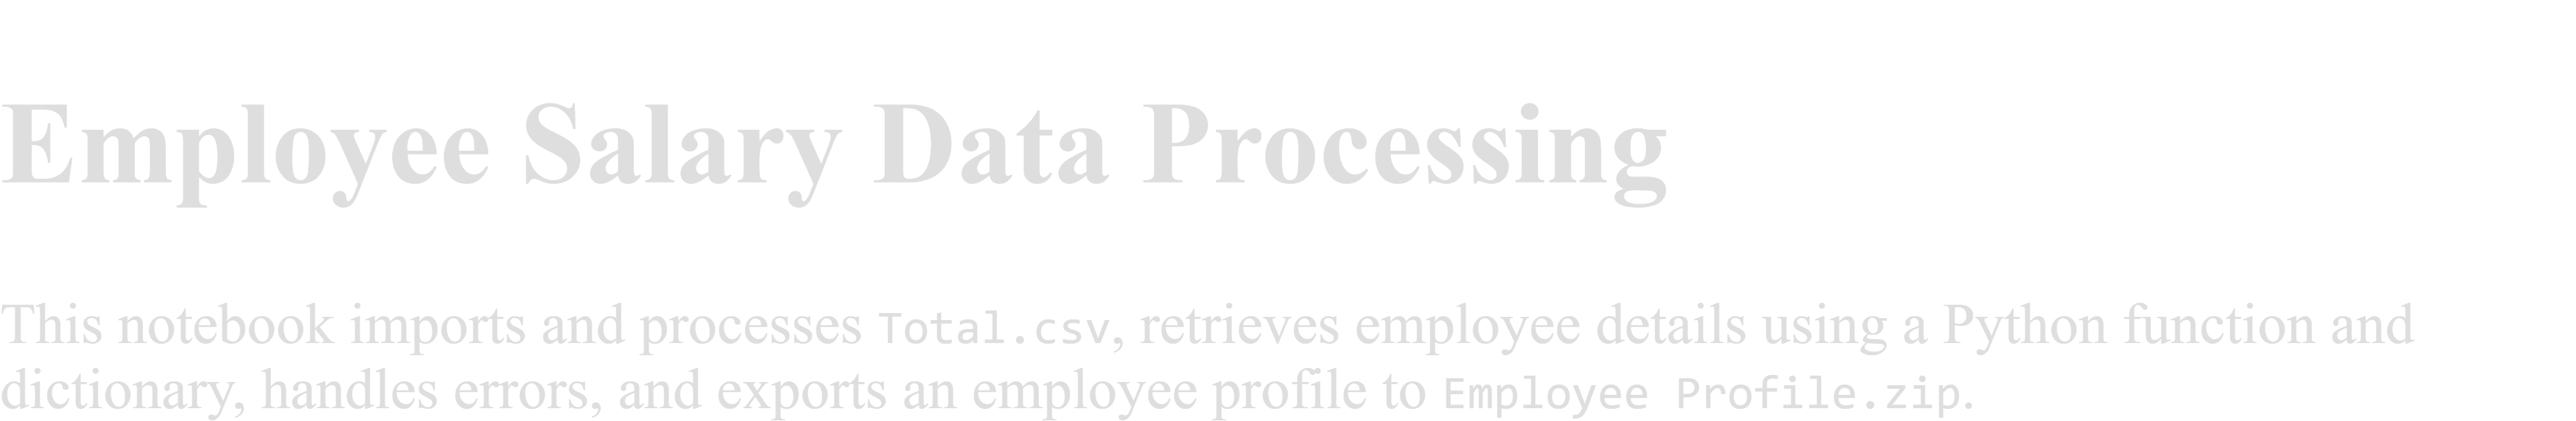

In [1]:
# Import the libraries required for data and file processing
import pandas as pd
from pathlib import Path
import zipfile

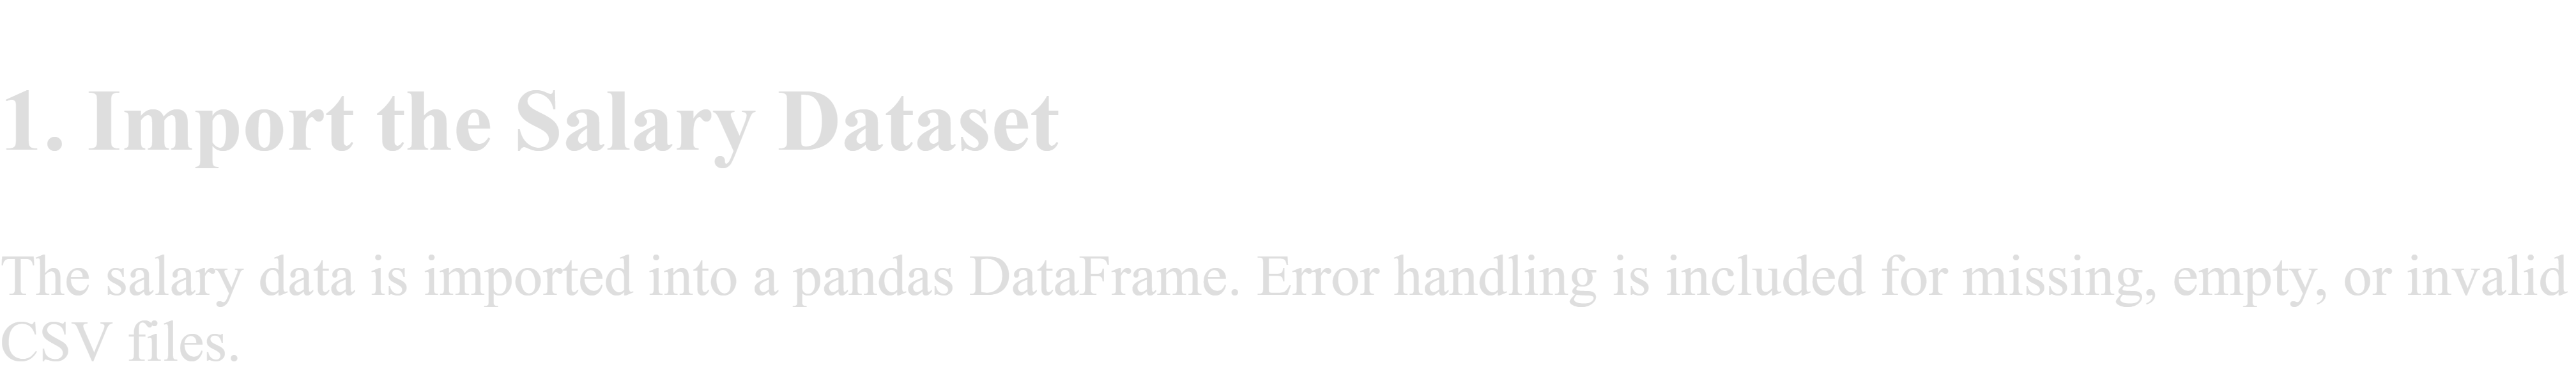

In [2]:
# Store the CSV filename in a Path object
salary_file = Path("Total.csv")

try:
    # Import the salary data into a pandas DataFrame
    salary_data = pd.read_csv(salary_file)

    # Confirm that the import was successful
    print("Salary data imported successfully.")
    print(f"Number of rows: {salary_data.shape[0]:,}")
    print(f"Number of columns: {salary_data.shape[1]}")

except FileNotFoundError:
    print(
        "Error: Total.csv could not be found. "
        "Place the CSV file in the same folder as the notebook."
    )

except pd.errors.EmptyDataError:
    print("Error: Total.csv is empty.")

except pd.errors.ParserError:
    print("Error: Total.csv could not be parsed correctly.")

except Exception as error:
    print(f"An unexpected error occurred: {error}")

Salary data imported successfully.
Number of rows: 312,882
Number of columns: 9


C:\Users\User\AppData\Local\Temp\ipykernel_1292\2423278715.py:6: DtypeWarning: Columns (2: BasePay, 3: OvertimePay, 4: OtherPay, 5: Benefits) have mixed types. Specify dtype option on import or set low_memory=False.
  salary_data = pd.read_csv(salary_file)


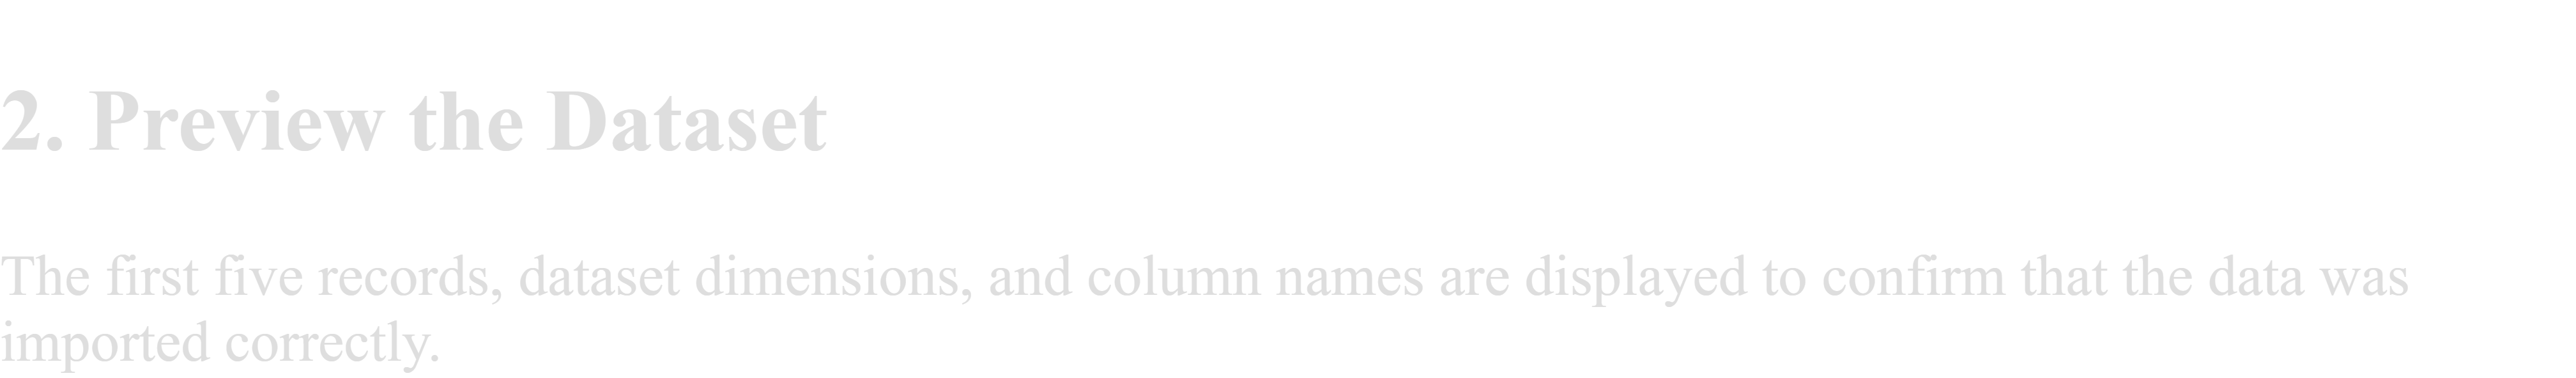

In [3]:
# Display the first five records
salary_data.head()

,EmployeeName,JobTitle,BasePay,OvertimePay,OtherPay,Benefits,TotalPay,TotalPayBenefits,Year
0,NATHANIEL FORD,GENERAL MANAGER-METROPOLITAN TRANSIT AUTHORITY,167411.18,0.0,400184.25,Not Provided,567595.43,567595.43,2011
1,GARY JIMENEZ,CAPTAIN III (POLICE DEPARTMENT),155966.02,245131.88,137811.38,Not Provided,538909.28,538909.28,2011
2,ALBERT PARDINI,CAPTAIN III (POLICE DEPARTMENT),212739.13,106088.18,16452.6,Not Provided,335279.91,335279.91,2011
3,CHRISTOPHER CHONG,WIRE ROPE CABLE MAINTENANCE MECHANIC,77916.0,56120.71,198306.9,Not Provided,332343.61,332343.61,2011
4,PATRICK GARDNER,"DEPUTY CHIEF OF DEPARTMENT,(FIRE DEPARTMENT)",134401.6,9737.0,182234.59,Not Provided,326373.19,326373.19,2011


In [4]:
# Display all column names in the dataset
print("Dataset columns:")

for column in salary_data.columns:
    print(f"- {column}")

Dataset columns:
- EmployeeName
- JobTitle
- BasePay
- OvertimePay
- OtherPay
- Benefits
- TotalPay
- TotalPayBenefits
- Year


In [5]:
# Display the dataset dimensions clearly
number_of_rows, number_of_columns = salary_data.shape

print(f"The dataset contains {number_of_rows:,} rows.")
print(f"The dataset contains {number_of_columns} columns.")

The dataset contains 312,882 rows.
The dataset contains 9 columns.


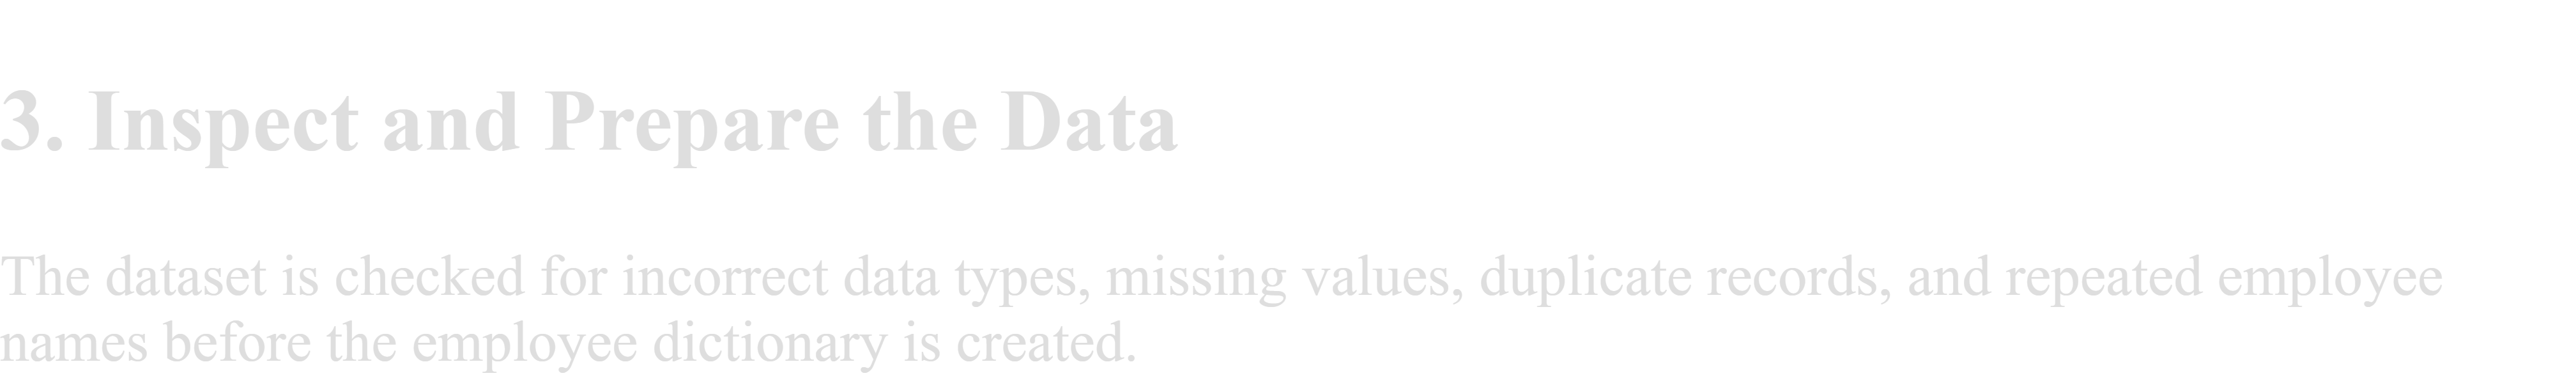

In [6]:
# Confirm that the salary dataset is available
if "salary_data" in globals():
    print("The salary_data DataFrame is available.")
    print(f"Dataset size: {salary_data.shape[0]:,} rows and {salary_data.shape[1]} columns.")
else:
    print("The salary dataset is not available. Run the import cell first.")

The salary_data DataFrame is available.
Dataset size: 312,882 rows and 9 columns.


In [7]:
# Display the data type of every column
salary_data.dtypes

EmployeeName            str
JobTitle                str
BasePay              object
OvertimePay          object
OtherPay             object
Benefits             object
TotalPay            float64
TotalPayBenefits    float64
Year                  int64
dtype: object

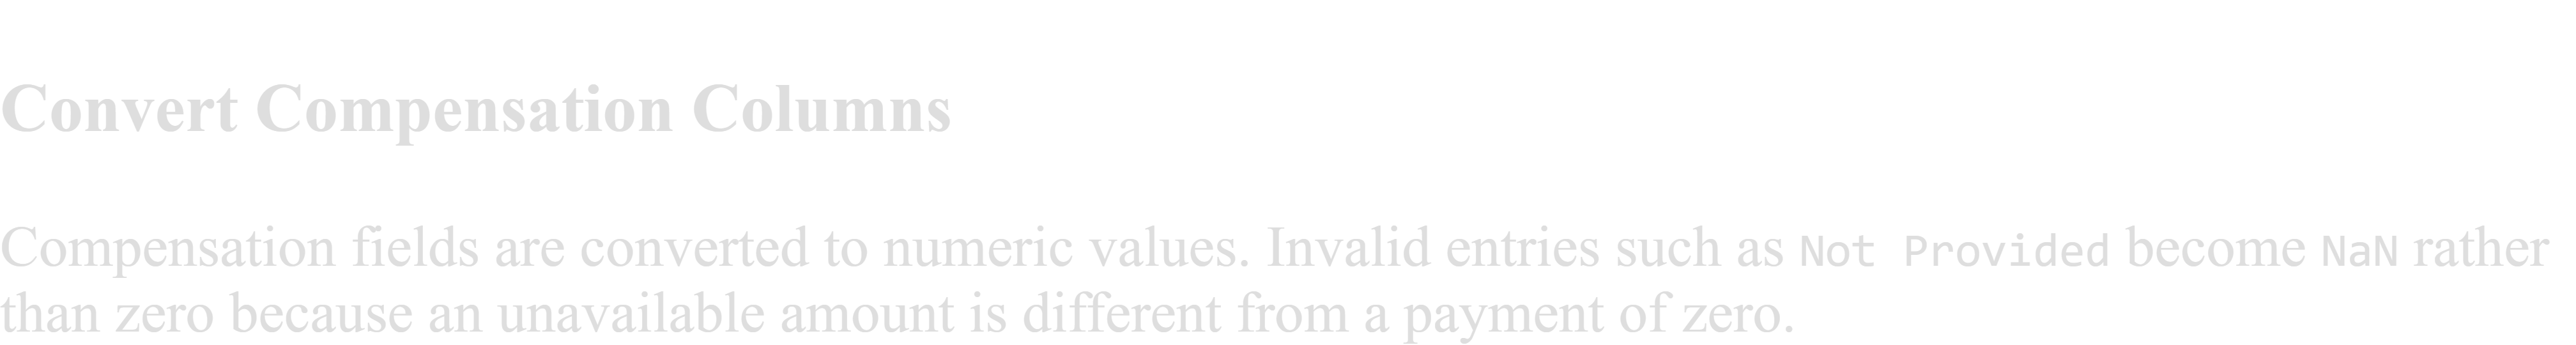

In [8]:
# Identify the compensation columns that should be numeric
numeric_columns = [
    "BasePay",
    "OvertimePay",
    "OtherPay",
    "Benefits",
    "TotalPay",
    "TotalPayBenefits"
]

# Convert the compensation columns to numeric values
for column in numeric_columns:
    salary_data[column] = pd.to_numeric(
        salary_data[column],
        errors="coerce"
    )

# Confirm the updated data types
salary_data[numeric_columns].dtypes

BasePay             float64
OvertimePay         float64
OtherPay            float64
Benefits            float64
TotalPay            float64
TotalPayBenefits    float64
dtype: object

In [9]:
# Display column names, non-null counts, and data types
salary_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 312882 entries, 0 to 312881
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   EmployeeName      312882 non-null  str    
 1   JobTitle          312882 non-null  str    
 2   BasePay           312276 non-null  float64
 3   OvertimePay       312881 non-null  float64
 4   OtherPay          312881 non-null  float64
 5   Benefits          276722 non-null  float64
 6   TotalPay          312882 non-null  float64
 7   TotalPayBenefits  312882 non-null  float64
 8   Year              312882 non-null  int64  
dtypes: float64(6), int64(1), str(2)
memory usage: 21.5 MB


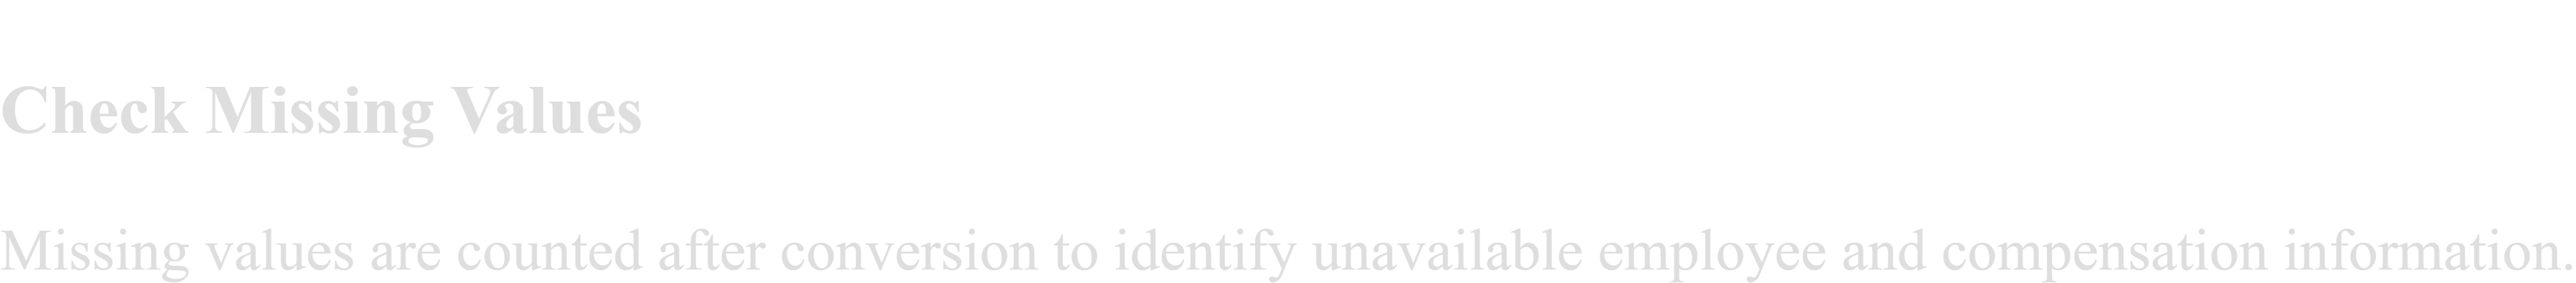

In [10]:
# Count standard missing values in every column
missing_values = salary_data.isna().sum()

# Display the missing-value count
print("Standard missing values by column:")
print(missing_values)

Standard missing values by column:
EmployeeName            0
JobTitle                0
BasePay               606
OvertimePay             1
OtherPay                1
Benefits            36160
TotalPay                0
TotalPayBenefits        0
Year                    0
dtype: int64


In [11]:
# Keep only columns containing missing values
columns_with_missing_values = missing_values[missing_values > 0]

if columns_with_missing_values.empty:
    print("No missing values were found.")
else:
    print("Columns containing missing values:")
    print(columns_with_missing_values)

Columns containing missing values:
BasePay          606
OvertimePay        1
OtherPay           1
Benefits       36160
dtype: int64


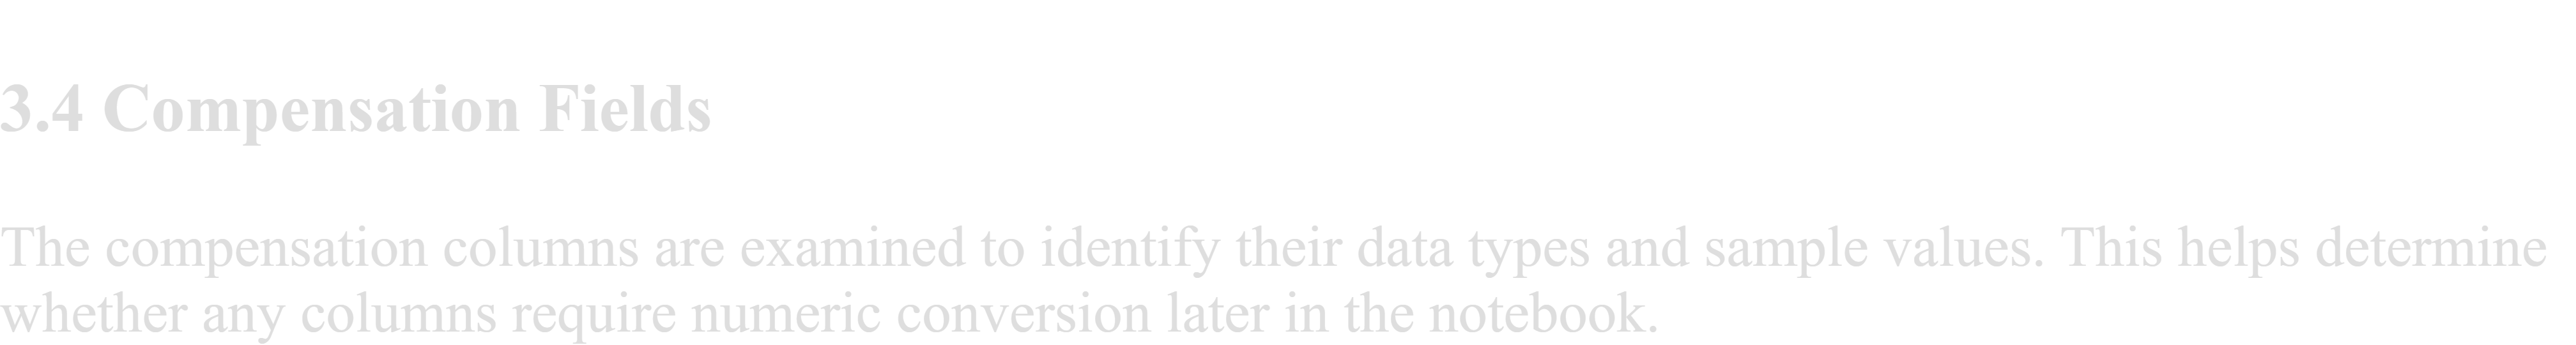

In [12]:
# Identify the compensation columns in the dataset
compensation_columns = [
    "BasePay",
    "OvertimePay",
    "OtherPay",
    "Benefits",
    "TotalPay",
    "TotalPayBenefits"
]

# Display the data type of each compensation column
print("Compensation column data types:")
print(salary_data[compensation_columns].dtypes)

Compensation column data types:
BasePay             float64
OvertimePay         float64
OtherPay            float64
Benefits            float64
TotalPay            float64
TotalPayBenefits    float64
dtype: object


In [13]:
# Display sample compensation values
salary_data[compensation_columns].head()

,BasePay,OvertimePay,OtherPay,Benefits,TotalPay,TotalPayBenefits
0,167411.18,0.00,400184.25,NaN,567595.43,567595.43
1,155966.02,245131.88,137811.38,NaN,538909.28,538909.28
2,212739.13,106088.18,16452.60,NaN,335279.91,335279.91
3,77916.00,56120.71,198306.90,NaN,332343.61,332343.61
4,134401.60,9737.00,182234.59,NaN,326373.19,326373.19


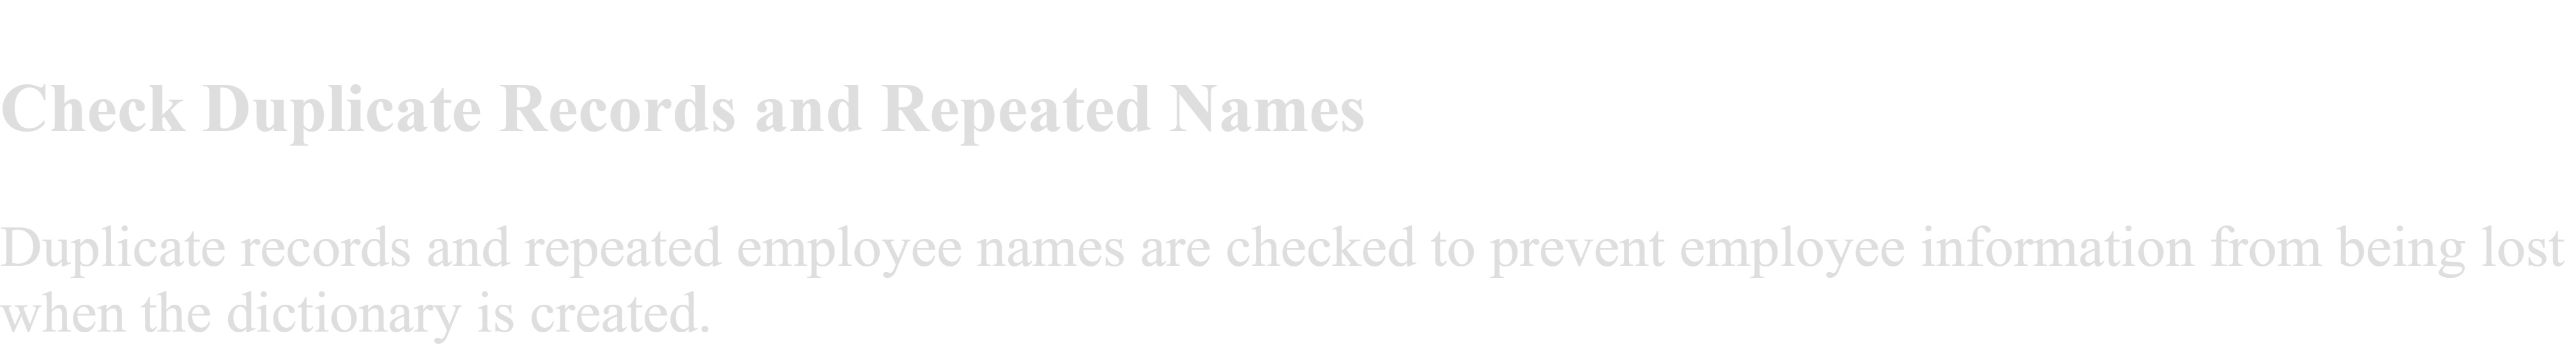

In [14]:
# Count completely duplicated rows
complete_duplicate_count = salary_data.duplicated().sum()

print(f"Number of completely duplicated rows: {complete_duplicate_count:,}")

Number of completely duplicated rows: 0


In [15]:
# Count the number of records associated with each employee name
employee_name_counts = salary_data["EmployeeName"].value_counts()

# Keep names that appear more than once
repeated_employee_names = employee_name_counts[employee_name_counts > 1]

print(f"Number of unique employee names: {salary_data['EmployeeName'].nunique():,}")
print(f"Number of names appearing more than once: {len(repeated_employee_names):,}")
print(f"Number of records linked to repeated names: {repeated_employee_names.sum():,}")

Number of unique employee names: 130,283
Number of names appearing more than once: 52,118
Number of records linked to repeated names: 234,717


In [16]:
# Display a sample of the most frequently repeated employee names
repeated_employee_names.head(10)

EmployeeName
Steven Lee                29
Kevin Lee                 29
Michael Wong              25
Victor Lee                23
William Wong              22
Amelie E Bullard          22
Richard Lee               21
John Chan                 21
Douglas R Price-Hanson    18
Emelita M Hathaway        18
Name: count, dtype: int64

In [17]:
# Select one repeated name for inspection
if not repeated_employee_names.empty:
    sample_repeated_name = repeated_employee_names.index[0]

    print(f"Sample repeated employee name: {sample_repeated_name}")
    print(
        f"Number of records for this name: "
        f"{repeated_employee_names.iloc[0]}"
    )

    sample_repeated_records = salary_data[
        salary_data["EmployeeName"] == sample_repeated_name
    ]

    display(sample_repeated_records)
else:
    print("No repeated employee names were found.")

Sample repeated employee name: Steven Lee
Number of records for this name: 29


,EmployeeName,JobTitle,BasePay,OvertimePay,OtherPay,Benefits,TotalPay,TotalPayBenefits,Year
37780,Steven Lee,"Manager VII, MTA",156161.65,0.00,3486.00,53266.41,159647.65,212914.06,2012
38670,Steven Lee,Police Officer 3,120350.02,15033.21,22919.20,38171.85,158302.43,196474.28,2012
41415,Steven Lee,Engineer,123747.05,0.00,0.00,44944.40,123747.05,168691.45,2012
44943,Steven Lee,Transit Operator,67514.34,28047.08,7509.60,41851.69,103071.02,144922.71,2012
46443,Steven Lee,IS Administrator 3,97461.00,0.00,0.00,37992.28,97461.00,135453.28,2012
58951,Steven Lee,Security Guard,47284.00,3283.11,6464.25,28409.91,57031.36,85441.27,2012
111964,Steven Lee,"Manager VII, MTA",164725.06,0.00,1500.00,58633.80,166225.06,224858.86,2014
116355,Steven Lee,Engineer,128556.53,0.00,0.00,41043.52,128556.53,169600.05,2014
120545,Steven Lee,IT Operations Support Admin IV,103180.00,0.00,0.00,36412.57,103180.00,139592.57,2014
121035,Steven Lee,Transit Operator,68203.86,26695.36,5275.82,36824.65,100175.04,136999.69,2014


In [18]:
# Check repeated combinations of employee name and year
duplicate_name_year_mask = salary_data.duplicated(
    subset=["EmployeeName", "Year"],
    keep=False
)

duplicate_name_year_records = salary_data[duplicate_name_year_mask]

print(
    "Number of records with repeated EmployeeName and Year combinations: "
    f"{len(duplicate_name_year_records):,}"
)

Number of records with repeated EmployeeName and Year combinations: 26,345


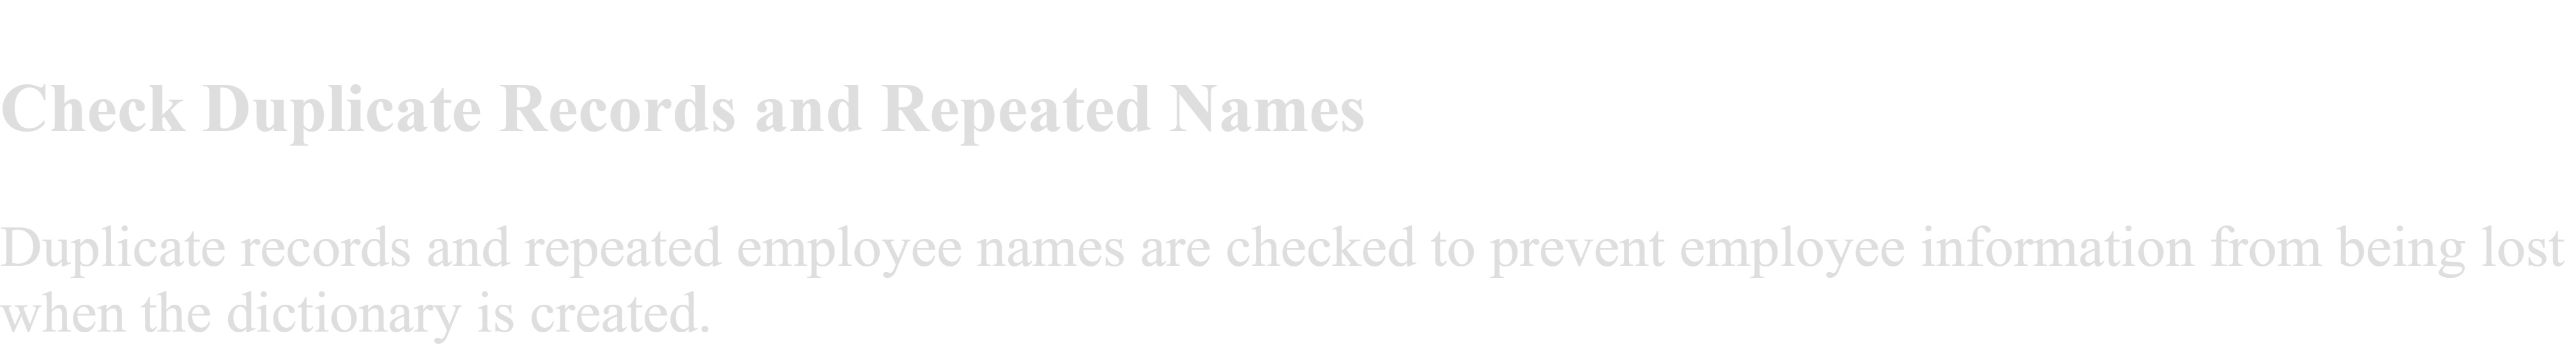

In [19]:
# Display a small sample of repeated name and year records
duplicate_name_year_records[
    ["EmployeeName", "JobTitle", "Year", "TotalPay"]
].sort_values(
    by=["EmployeeName", "Year"]
).head(10)

,EmployeeName,JobTitle,Year,TotalPay
8185,AARON CRAMER,REGISTERED NURSE,2011,106385.49
28892,AARON CRAMER,SPECIAL NURSE,2011,23108.64
14948,AARON RAINEY,REGISTERED NURSE,2011,78260.44
35414,AARON RAINEY,SPECIAL NURSE,2011,917.53
2154,AARON STEVENSON,"LIEUTENANT, FIRE DEPARTMENT",2011,151038.37
16285,AARON STEVENSON,"ASSISTANT CHIEF OF DEPARTMENT, (FIRE DEPARTMENT)",2011,73444.97
21978,ABELARDO GOMEZ,TRANSIT OPERATOR,2011,57650.46
34053,ABELARDO GOMEZ,TRANSIT OPERATOR,2011,3415.60
12988,ADRIENNE BARBAS,REGISTERED NURSE,2011,84855.62
28567,ADRIENNE BARBAS,SPECIAL NURSE,2011,25546.64


In [20]:
# Count employee names that are missing or contain only spaces
missing_employee_names = salary_data["EmployeeName"].isna().sum()

blank_employee_names = (
    salary_data["EmployeeName"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print(f"Missing EmployeeName values: {missing_employee_names:,}")
print(f"Blank EmployeeName values: {blank_employee_names:,}")

Missing EmployeeName values: 0
Blank EmployeeName values: 0


In [21]:
# Display the years represented in the dataset
available_years = sorted(salary_data["Year"].dropna().unique())

print("Years included in the dataset:")
print(available_years)

print(f"Number of distinct years: {salary_data['Year'].nunique()}")

Years included in the dataset:
[np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018)]
Number of distinct years: 8


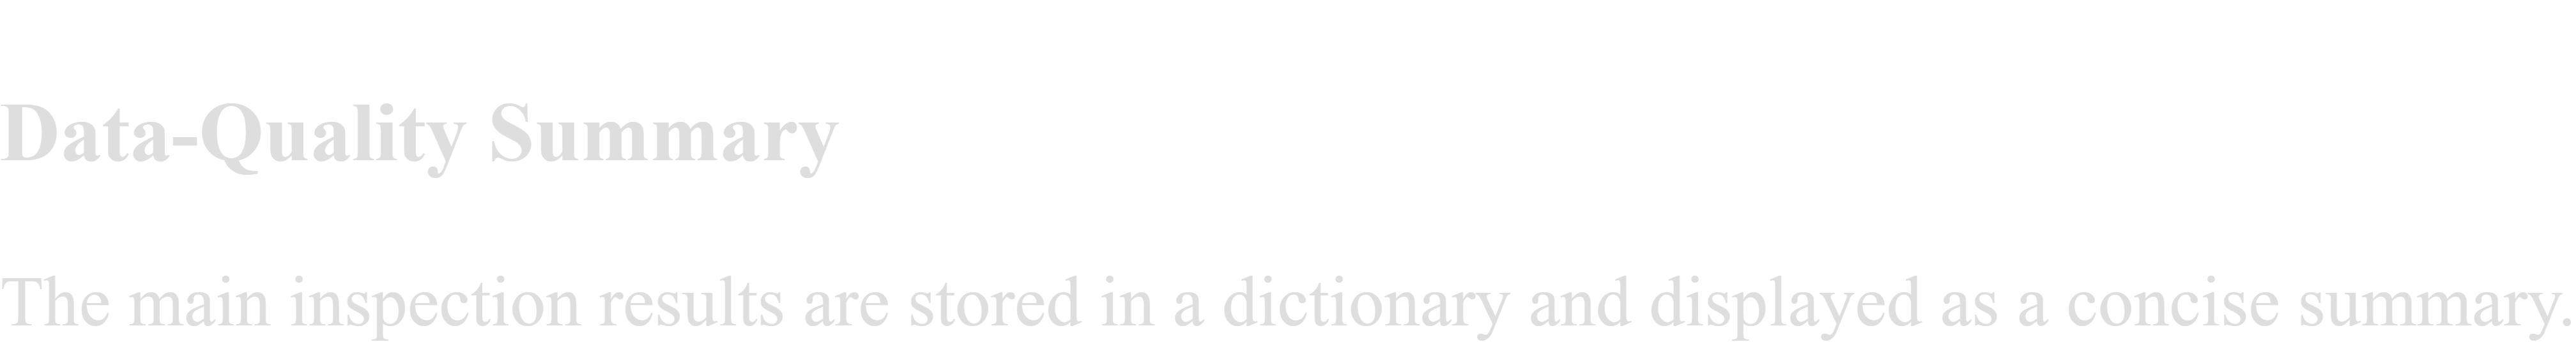

In [22]:
# Create a dictionary containing the main inspection results
data_quality_summary = {
    "Number of rows": salary_data.shape[0],
    "Number of columns": salary_data.shape[1],
    "Complete duplicate rows": int(complete_duplicate_count),
    "Unique employee names": salary_data["EmployeeName"].nunique(),
    "Repeated employee names": len(repeated_employee_names),
    "Missing employee names": int(missing_employee_names),
    "Blank employee names": int(blank_employee_names),
    "Distinct years": salary_data["Year"].nunique()
}

# Display the summary clearly
for check, result in data_quality_summary.items():
    if isinstance(result, int):
        print(f"{check}: {result:,}")
    else:
        print(f"{check}: {result}")

Number of rows: 312,882
Number of columns: 9
Complete duplicate rows: 0
Unique employee names: 130,283
Repeated employee names: 52,118
Missing employee names: 0
Blank employee names: 0
Distinct years: 8


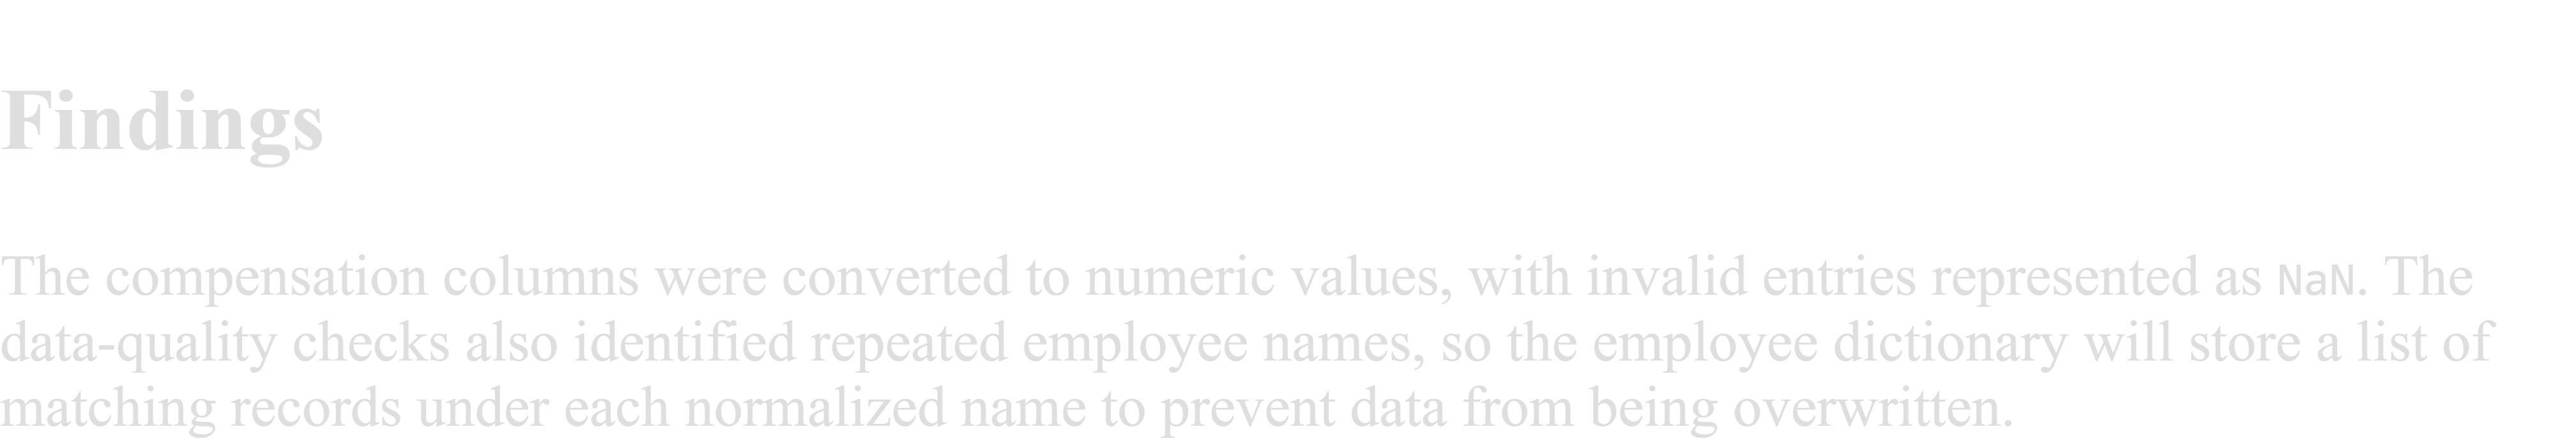

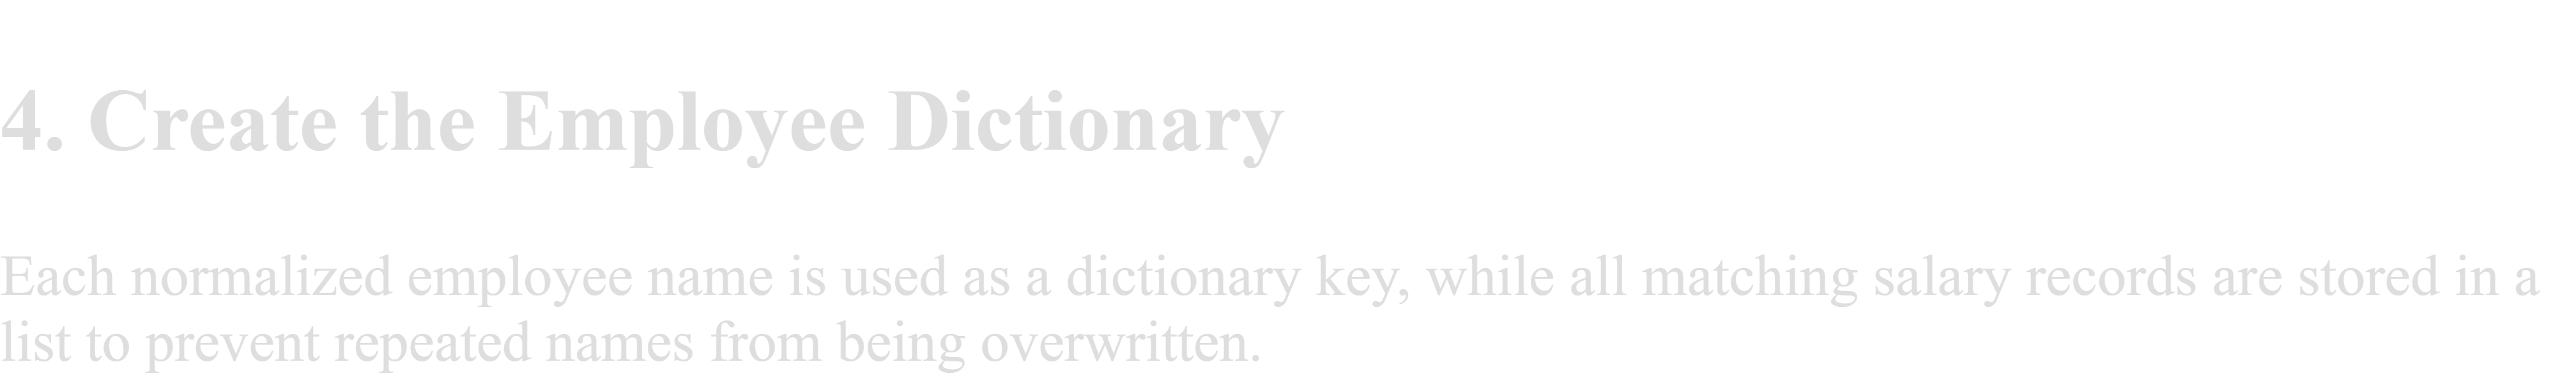

In [23]:
# Create an empty dictionary for the employee records
employee_dictionary = {}

# Convert the DataFrame rows into dictionaries
employee_records = salary_data.to_dict(orient="records")

# Process every employee record
for employee_record in employee_records:
    # Get the employee name from the current record
    employee_name = employee_record.get("EmployeeName")
    # Skip records with missing employee names
    if pd.isna(employee_name):
        continue
    # Remove extra spaces from the original employee name
    employee_name = str(employee_name).strip()
    # Skip records with blank employee names
    if employee_name == "":
        continue
    # Preserve the cleaned original name in the employee record
    employee_record["EmployeeName"] = employee_name
    # Create a lowercase name for dictionary searching
    normalized_name = employee_name.lower()
    # Create an empty list if the name is not already a key
    employee_dictionary.setdefault(normalized_name, [])
    # Add the employee record to the matching name
    employee_dictionary[normalized_name].append(employee_record)
print("Employee dictionary created successfully.")

Employee dictionary created successfully.


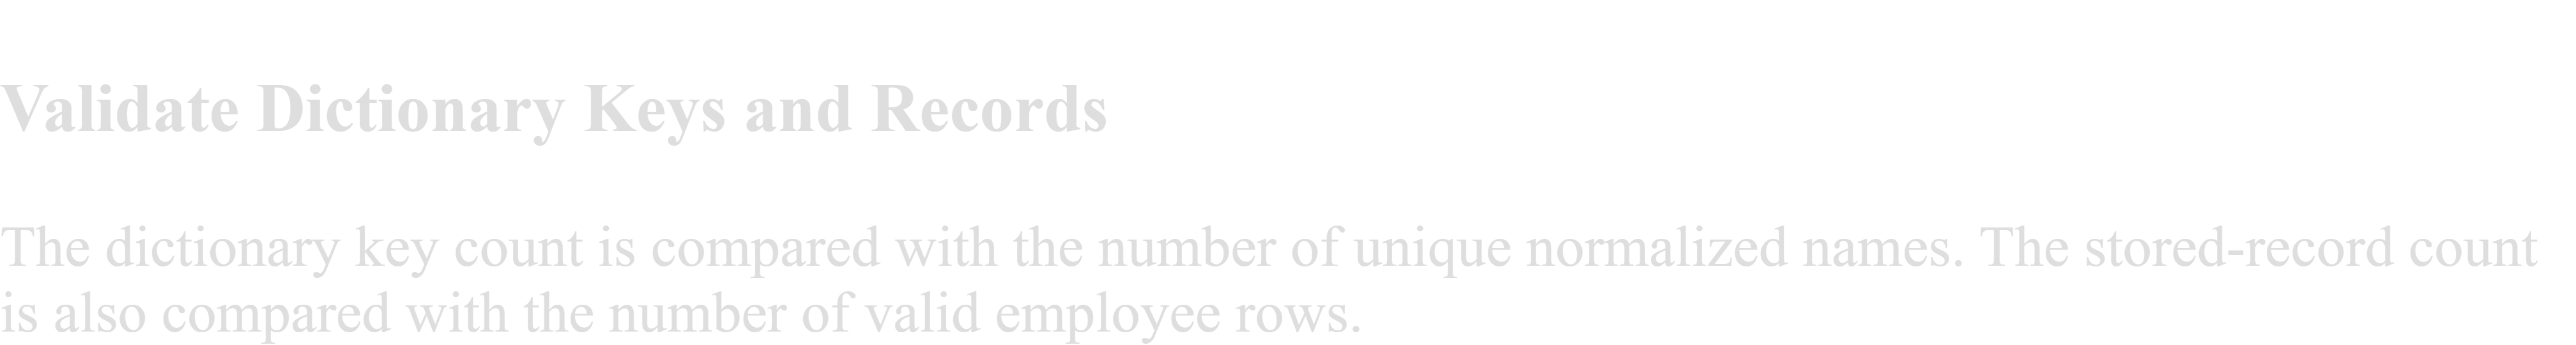

In [24]:
# Create a cleaned series of employee names
normalized_employee_names = (
    salary_data["EmployeeName"]
    .dropna()
    .astype(str)
    .str.strip()
)

# Remove blank employee names
normalized_employee_names = normalized_employee_names[
    normalized_employee_names != ""
]

# Convert the names to lowercase
normalized_employee_names = (
    normalized_employee_names.str.lower()
)

# Count the unique normalized names
normalized_unique_name_count = (
    normalized_employee_names.nunique()
)

In [25]:
# Select DataFrame rows containing valid employee names
valid_employee_rows = salary_data[
    salary_data["EmployeeName"].notna()
    & salary_data["EmployeeName"]
        .astype(str)
        .str.strip()
        .ne("")
]

# Count the valid employee rows
valid_employee_row_count = len(
    valid_employee_rows
)

In [26]:
# Count the normalized names used as dictionary keys
dictionary_key_count = len(
    employee_dictionary
)

# Count every employee record stored in the dictionary
dictionary_record_count = sum(
    len(records)
    for records in employee_dictionary.values()
)

In [27]:
# Display the dictionary validation counts
print(
    f"Original unique names: "
    f"{salary_data['EmployeeName'].nunique():,}"
)

print(
    f"Normalized unique names: "
    f"{normalized_unique_name_count:,}"
)

print(
    f"Dictionary keys: "
    f"{dictionary_key_count:,}"
)

print(
    f"Valid DataFrame records: "
    f"{valid_employee_row_count:,}"
)

print(
    f"Dictionary records stored: "
    f"{dictionary_record_count:,}"
)

Original unique names: 130,283
Normalized unique names: 99,865
Dictionary keys: 99,865
Valid DataFrame records: 312,882
Dictionary records stored: 312,882


In [28]:
# Validate the dictionary key count
if dictionary_key_count == normalized_unique_name_count:
    print(
        "Dictionary key validation successful."
    )
else:
    print(
        "Validation warning: Dictionary keys do not "
        "match the normalized unique-name count."
    )

# Validate the stored employee record count
if dictionary_record_count == valid_employee_row_count:
    print(
        "Dictionary record validation successful."
    )
else:
    print(
        "Validation warning: Some valid employee "
        "records may be missing."
    )

Dictionary key validation successful.
Dictionary record validation successful.


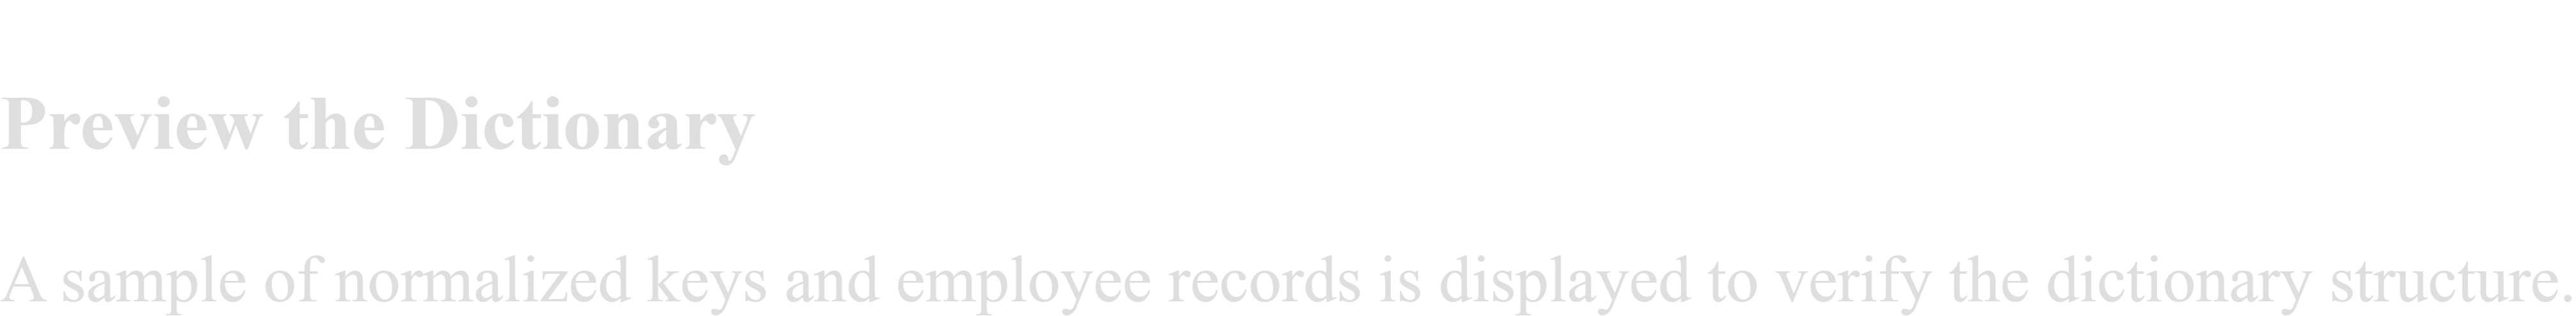

In [29]:
# Select the first five normalized dictionary keys
first_five_names = list(
    employee_dictionary.keys()
)[:5]

print("First five dictionary keys:")

for employee_name in first_five_names:
    print(f"- {employee_name}")

First five dictionary keys:
- nathaniel ford
- gary jimenez
- albert pardini
- christopher chong
- patrick gardner


In [30]:
# Select the first dictionary key
sample_employee_key = next(
    iter(employee_dictionary)
)

# Retrieve all records stored under the selected name
sample_employee_records = employee_dictionary[
    sample_employee_key
]

print(
    f"Dictionary key: "
    f"{sample_employee_key}"
)

print(
    f"Number of matching records: "
    f"{len(sample_employee_records)}"
)

# Display the matching records as a DataFrame
display(
    pd.DataFrame(sample_employee_records)
)

Dictionary key: nathaniel ford
Number of matching records: 1


,EmployeeName,JobTitle,BasePay,OvertimePay,OtherPay,Benefits,TotalPay,TotalPayBenefits,Year
0,NATHANIEL FORD,GENERAL MANAGER-METROPOLITAN TRANSIT AUTHORITY,167411.18,0.0,400184.25,NaN,567595.43,567595.43,2011


In [31]:
# Inspect one employee name containing multiple records
repeated_dictionary_names = {
    name: records
    for name, records in employee_dictionary.items()
    if len(records) > 1
}

if repeated_dictionary_names:

    # Select the first repeated dictionary name
    repeated_name_key = next(
        iter(repeated_dictionary_names)
    )

    # Retrieve all records stored under the name
    repeated_name_records = (
        repeated_dictionary_names[
            repeated_name_key
        ]
    )

    print(
        f"Normalized employee name: "
        f"{repeated_name_key}"
    )

    print(
        f"Records stored under this name: "
        f"{len(repeated_name_records)}"
    )

    # Display every matching record
    display(
        pd.DataFrame(repeated_name_records)
    )

else:
    print(
        "No normalized employee name contains "
        "multiple records."
    )

Normalized employee name: albert pardini
Records stored under this name: 2


,EmployeeName,JobTitle,BasePay,OvertimePay,OtherPay,Benefits,TotalPay,TotalPayBenefits,Year
0,ALBERT PARDINI,CAPTAIN III (POLICE DEPARTMENT),212739.13,106088.18,16452.60,NaN,335279.91,335279.91,2011
1,Albert Pardini,Captain 3,196265.04,0.00,11404.04,46326.21,207669.08,253995.29,2012


In [32]:
# Confirm that every dictionary value is a list
all_values_are_lists = all(
    isinstance(records, list)
    for records in employee_dictionary.values()
)

if all_values_are_lists:
    print(
        "Validation successful: every dictionary "
        "value is a list."
    )
else:
    print(
        "Validation warning: one or more dictionary "
        "values are not lists."
    )

Validation successful: every dictionary value is a list.


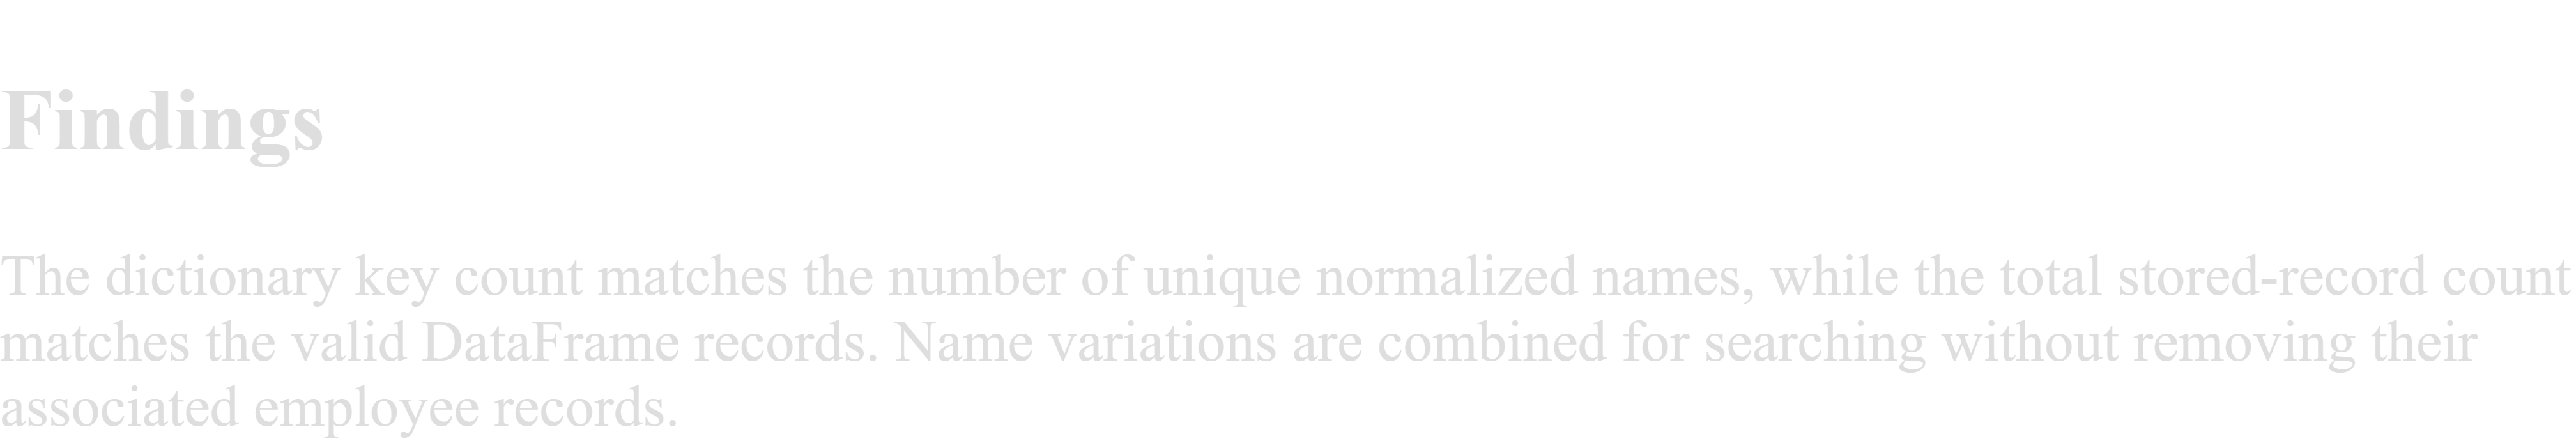

## 5. Creating the Employee Lookup Function ##

The function accepts an employee name, performs a case-insensitive dictionary search, and returns all matching records. Error handling addresses empty, non-text, and unavailable employee names.

In [33]:
# Define a function that returns employee details by name
def get_employee_details(employee_name):
    try:
        # Check that the employee name is text
        if not isinstance(employee_name, str):
            raise TypeError(
                "Employee name must be entered as text."
            )
        # Remove extra spaces from the name
        employee_name = employee_name.strip()

        # Check that the employee name is not blank
        if employee_name == "":
            raise ValueError(
                "Employee name cannot be empty."
            )

        # Normalize the name for dictionary searching
        normalized_name = employee_name.lower()

        # Retrieve all records stored under the name
        employee_details = employee_dictionary.get(
            normalized_name
        )

        # Check whether the employee exists
        if employee_details is None:
            raise KeyError(
                f"No employee named '{employee_name}' was found."
            )

        # Return every matching employee record
        return employee_details

    except TypeError as error:
        print(f"Type error: {error}")

    except ValueError as error:
        print(f"Value error: {error}")

    except KeyError as error:
        print(f"Search error: {error}")

    except Exception as error:
        print(f"An unexpected error occurred: {error}")

    # Return an empty list when the search is unsuccessful
    return []

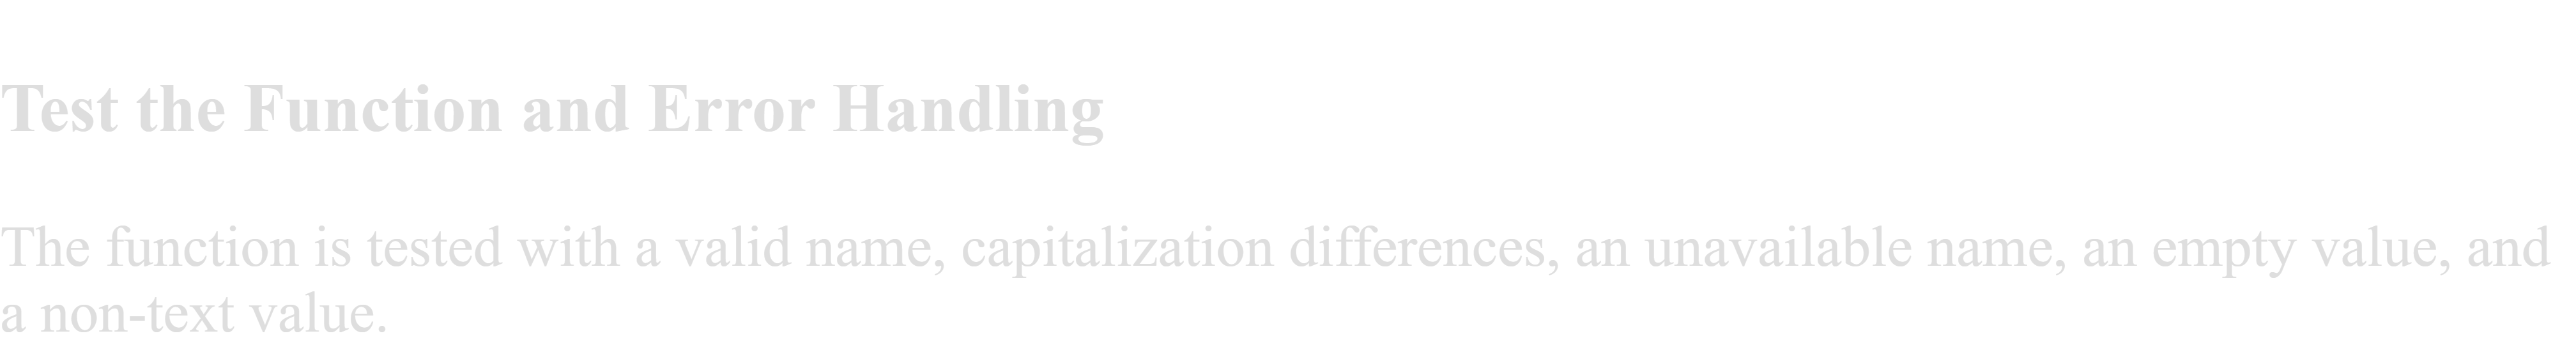

In [34]:
# Test the function with a valid employee name
selected_employee_name = "NATHANIEL FORD"

employee_details = get_employee_details(
    selected_employee_name
)

if employee_details:
    print(
        f"Records found for {selected_employee_name}: "
        f"{len(employee_details)}"
    )

    display(
        pd.DataFrame(employee_details)
    )

Records found for NATHANIEL FORD: 1


,EmployeeName,JobTitle,BasePay,OvertimePay,OtherPay,Benefits,TotalPay,TotalPayBenefits,Year
0,NATHANIEL FORD,GENERAL MANAGER-METROPOLITAN TRANSIT AUTHORITY,167411.18,0.0,400184.25,NaN,567595.43,567595.43,2011


In [35]:
# Test capitalization and common input errors
test_inputs = [
    "nathaniel ford",       # Lowercase valid name
    "  NATHANIEL FORD  ",   # Valid name with extra spaces
    "Employee Not Found",   # Unavailable name
    "",                     # Empty name
    12345                   # Non-text input
]

for test_input in test_inputs:
    print(f"\nTesting input: {repr(test_input)}")

    test_result = get_employee_details(
        test_input
    )

    if test_result:
        print(
            f"Successful match: "
            f"{len(test_result)} record(s) found."
        )


Testing input: 'nathaniel ford'
Successful match: 1 record(s) found.

Testing input: '  NATHANIEL FORD  '
Successful match: 1 record(s) found.

Testing input: 'Employee Not Found'
Search error: "No employee named 'Employee Not Found' was found."

Testing input: ''
Value error: Employee name cannot be empty.

Testing input: 12345
Type error: Employee name must be entered as text.


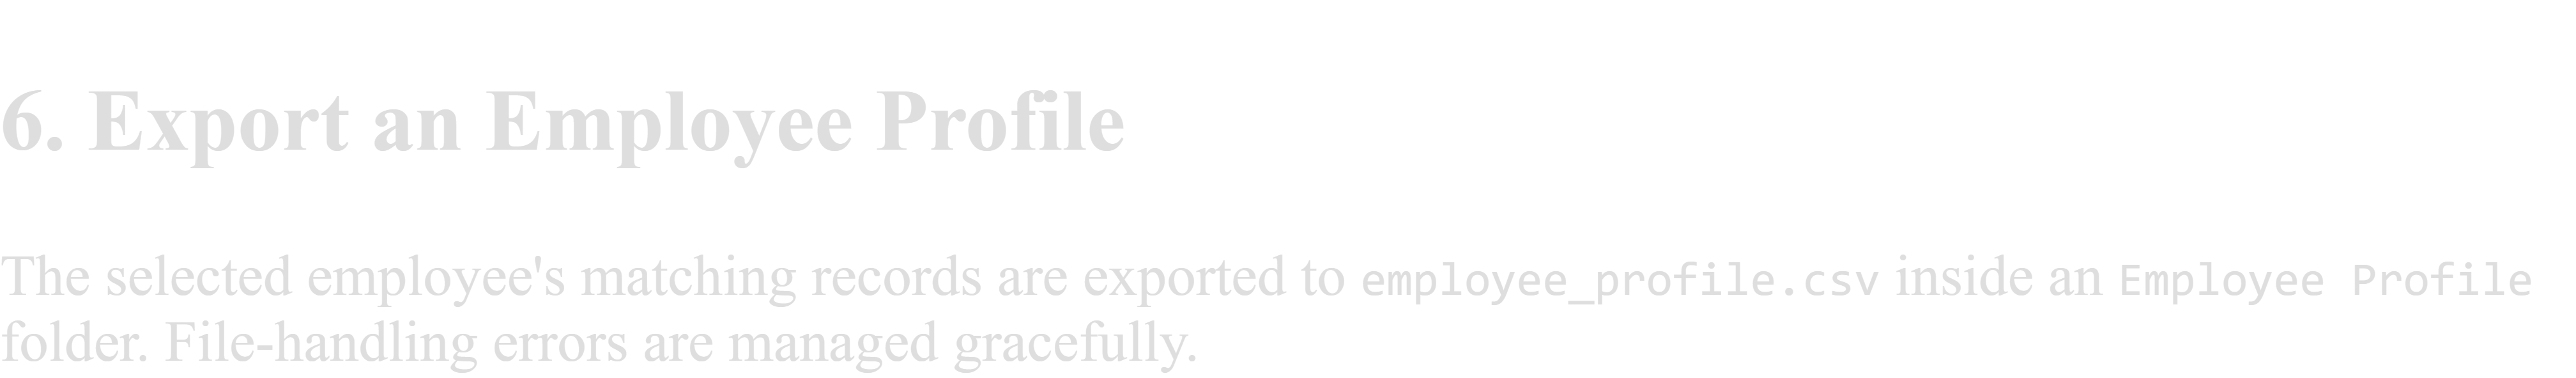

In [36]:
# Select a valid employee for export
export_employee_name = "NATHANIEL FORD"

# Define the folder and CSV file paths
profile_folder = Path("Employee Profile")
profile_csv = profile_folder / "employee_profile.csv"

try:
    # Retrieve all records matching the employee name
    export_employee_details = get_employee_details(
        export_employee_name
    )

    # Stop the export if no employee record was found
    if not export_employee_details:
        raise ValueError(
            "No employee details are available for export."
        )

    # Create the Employee Profile folder if necessary
    profile_folder.mkdir(
        exist_ok=True
    )

    # Convert the matching records into a DataFrame
    employee_profile_data = pd.DataFrame(
        export_employee_details
    )

    # Export the employee details to CSV
    employee_profile_data.to_csv(
        profile_csv,
        index=False
    )

    print("Employee profile exported successfully.")
    print(f"Employee name: {export_employee_name}")
    print(f"Records exported: {len(employee_profile_data)}")
    print(f"CSV file: {profile_csv}")

except ValueError as error:
    print(f"Export error: {error}")

except OSError as error:
    print(f"File error: {error}")

except Exception as error:
    print(f"An unexpected error occurred: {error}")

Employee profile exported successfully.
Employee name: NATHANIEL FORD
Records exported: 1
CSV file: Employee Profile\employee_profile.csv


In [37]:
# Confirm that the CSV file was created
if profile_csv.exists():

    # Read the exported CSV for verification
    exported_profile = pd.read_csv(
        profile_csv
    )

    print(
        f"Exported CSV rows: "
        f"{len(exported_profile)}"
    )

    display(exported_profile)

else:
    print(
        "Verification failed: "
        "employee_profile.csv was not found."
    )

Exported CSV rows: 1


,EmployeeName,JobTitle,BasePay,OvertimePay,OtherPay,Benefits,TotalPay,TotalPayBenefits,Year
0,NATHANIEL FORD,GENERAL MANAGER-METROPOLITAN TRANSIT AUTHORITY,167411.18,0.0,400184.25,NaN,567595.43,567595.43,2011


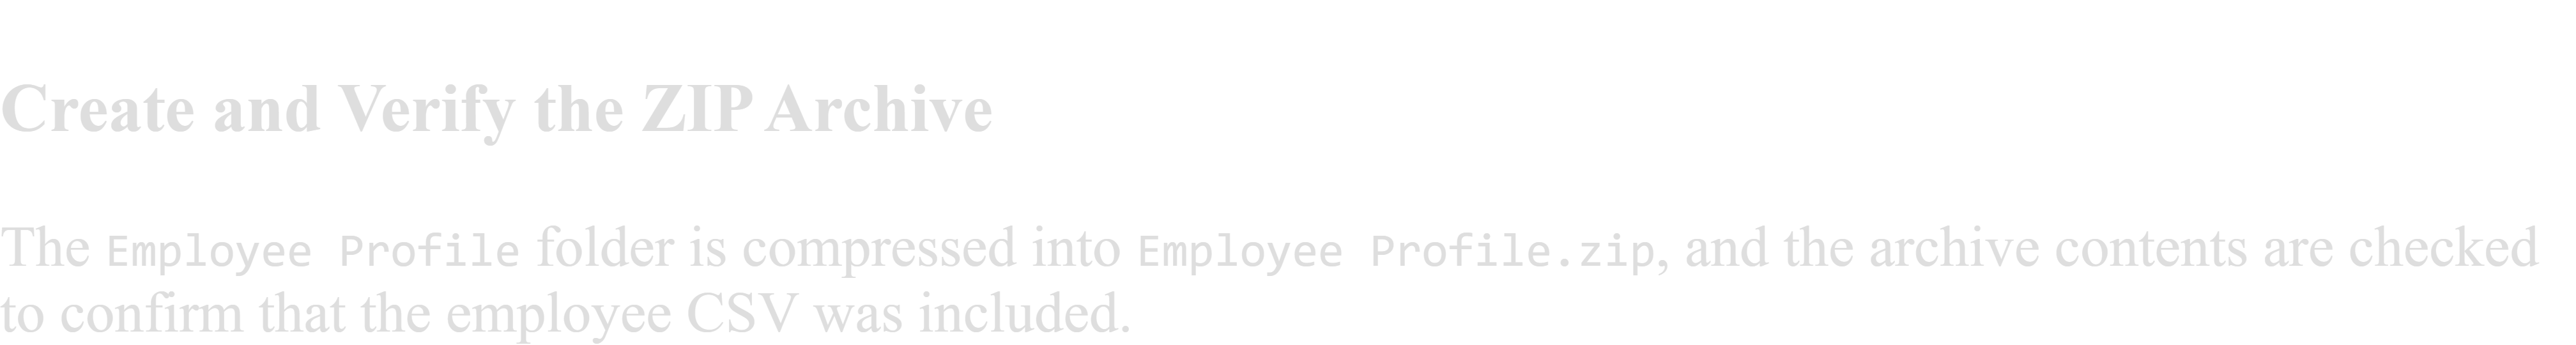

In [38]:
# Define the ZIP archive path
zip_file = Path("Employee Profile.zip")

try:
    # Create or replace the ZIP archive
    with zipfile.ZipFile(
        zip_file,
        mode="w",
        compression=zipfile.ZIP_DEFLATED
    ) as employee_zip:

        # Add the CSV inside an Employee Profile folder
        employee_zip.write(
            profile_csv,
            arcname=(
                Path("Employee Profile")
                / profile_csv.name
            )
        )

    # Reopen the ZIP archive to verify its contents
    with zipfile.ZipFile(
        zip_file,
        mode="r"
    ) as employee_zip:

        zip_contents = employee_zip.namelist()

    print("ZIP archive created successfully.")
    print(f"ZIP file: {zip_file}")
    print("Archive contents:")

    for file_name in zip_contents:
        print(f"- {file_name}")

    # Confirm that the employee CSV is inside the archive
    expected_file = (
        "Employee Profile/employee_profile.csv"
    )

    if expected_file in zip_contents:
        print(
            "Verification successful: "
            "employee_profile.csv is in the ZIP archive."
        )
    else:
        print(
            "Verification warning: "
            "employee_profile.csv was not found in the archive."
        )

except FileNotFoundError as error:
    print(f"ZIP creation error: {error}")

except PermissionError as error:
    print(f"Permission error: {error}")

except zipfile.BadZipFile as error:
    print(f"Invalid ZIP archive: {error}")

except OSError as error:
    print(f"File error: {error}")

except Exception as error:
    print(f"An unexpected error occurred: {error}")

ZIP archive created successfully.
ZIP file: Employee Profile.zip
Archive contents:
- Employee Profile/employee_profile.csv
Verification successful: employee_profile.csv is in the ZIP archive.


In [41]:
# Verify the main Python project requirements
requirement_checks = {
    "Salary data imported": (
        "salary_data" in globals()
        and not salary_data.empty
    ),
    "Employee dictionary created": (
        "employee_dictionary" in globals()
        and len(employee_dictionary) > 0
    ),
    "Employee lookup function created": (
        "get_employee_details" in globals()
        and callable(get_employee_details)
    ),
    "Employee profile CSV created": (
        profile_csv.exists()
    ),
    "Employee Profile ZIP created": (
        zip_file.exists()
    )
}

# Display the verification results
print("FINAL REQUIREMENT CHECK")
print("=" * 30)

for requirement, completed in requirement_checks.items():
    status = "Passed" if completed else "Failed"
    print(f"{requirement}: {status}")

FINAL REQUIREMENT CHECK
Salary data imported: Passed
Employee dictionary created: Passed
Employee lookup function created: Passed
Employee profile CSV created: Passed
Employee Profile ZIP created: Passed


In [42]:
# Verify the final ZIP archive and its contents
try:
    if not zip_file.exists():
        raise FileNotFoundError(
            "Employee Profile.zip was not found."
        )

    with zipfile.ZipFile(
        zip_file,
        mode="r"
    ) as employee_zip:

        zip_contents = employee_zip.namelist()

        # Test whether the ZIP archive is valid
        invalid_file = employee_zip.testzip()

    print("\nFINAL ZIP VERIFICATION")
    print("=" * 30)
    print(f"ZIP archive: {zip_file}")
    print("Archive contents:")

    for file_name in zip_contents:
        print(f"- {file_name}")

    if invalid_file is None:
        print("ZIP integrity check: Passed")
    else:
        print(
            f"ZIP integrity check failed: "
            f"{invalid_file} may be damaged."
        )

except FileNotFoundError as error:
    print(f"Verification error: {error}")

except zipfile.BadZipFile as error:
    print(f"Invalid ZIP archive: {error}")

except Exception as error:
    print(f"An unexpected error occurred: {error}")


FINAL ZIP VERIFICATION
ZIP archive: Employee Profile.zip
Archive contents:
- Employee Profile/employee_profile.csv
ZIP integrity check: Passed


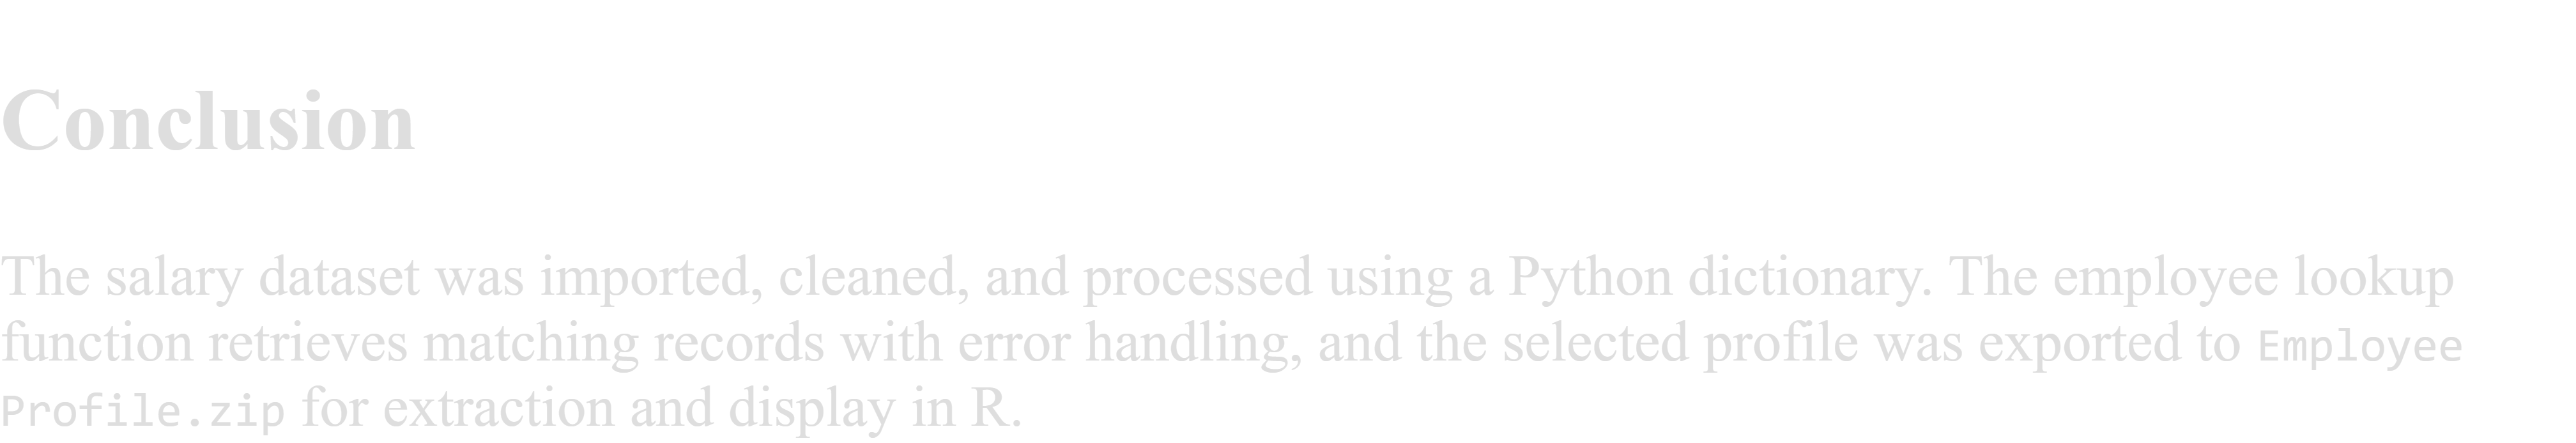